# EDA: Dados Hidrológicos de Balbina (ANEEL)

## Problema de Negócio
Prever a **vazão defluente** (`val_vazaodefluente`) da Usina Hidrelétrica de Balbina 
com base nas variáveis hidrológicas horárias coletadas pela ANEEL, permitindo 
antecipar a capacidade de geração de energia e apoiar decisões operacionais.

**Cliente fictício:** Operador do Sistema Elétrico Regional (Norte)  
**Métrica de sucesso:** RMSE < 50 m³/s e R² > 0,85  
**Tipo de problema:** Regressão  
**Fonte:** Portal de Dados Abertos da ANEEL – dados.gov.br  
**Período:** Janeiro/2025 a Maio/2026 (17 meses)  
**Total de registros:** 12.103 linhas horárias

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


## 1. Carregamento e Inspeção Inicial

In [2]:
# Carregamento do dataset consolidado
df = pd.read_csv("../data/raw/balbina_consolidado.csv", sep=";", encoding="utf-8-sig")

print("Shape:", df.shape)
print("\nTipos de dados:")
print(df.dtypes)

Shape: (12103, 22)

Tipos de dados:
id_subsistema                     object
nom_subsistema                    object
tip_reservatorio                  object
nom_bacia                         object
id_reservatorio                   object
nom_reservatorio                  object
cod_usina                        float64
din_instante                      object
val_nivelmontante                float64
val_niveljusante                 float64
val_volumeutil                   float64
val_vazaoafluente                float64
val_vazaodefluente               float64
val_vazaoturbinada               float64
val_vazaovertida                 float64
val_vazaooutrasestruturas        float64
val_vazaotransferida             float64
val_vazaovertidanaoturbinavel    float64
ano                                int64
mes                                int64
dia                                int64
hora                               int64
dtype: object


### Observações dos tipos de dados:
- `din_instante` está como `object` (string), precisa ser convertido para `datetime`
- `cod_usina` está como `float64`, poderia ser `int` pois é um código identificador
- `id_subsistema`, `nom_subsistema`, `tip_reservatorio`, `nom_bacia`, `id_reservatorio`, `nom_reservatorio` são colunas categóricas fixas (Balbina só tem um valor cada), serão removidas no pré-processamento pois não agregam informação ao modelo
- Colunas numéricas hidrológicas estão corretamente tipadas como `float64`

In [3]:
# Converter din_instante para datetime
df["din_instante"] = pd.to_datetime(df["din_instante"])

# Inspeção geral
print(df.describe(include="all").T)

                                 count unique                     top   freq  \
id_subsistema                    12103      2                       N   9441   
nom_subsistema                   12103      1                   Norte  12103   
tip_reservatorio                 12103      1  Reservatório com Usina  12103   
nom_bacia                        12103      1                AMAZONAS  12103   
id_reservatorio                  12103      1                  AMUHBB  12103   
nom_reservatorio                 12103      1                 BALBINA  12103   
cod_usina                      12103.0    NaN                     NaN    NaN   
din_instante                     12103    NaN                     NaN    NaN   
val_nivelmontante              12102.0    NaN                     NaN    NaN   
val_niveljusante               12102.0    NaN                     NaN    NaN   
val_volumeutil                 12102.0    NaN                     NaN    NaN   
val_vazaoafluente              12102.0  

### Observações do describe:
- `id_subsistema` tem 2 valores únicos apesar de ser sempre Balbina, investigar
- `nom_subsistema`, `tip_reservatorio`, `nom_bacia`, `id_reservatorio`, `nom_reservatorio` têm apenas 1 valor único, colunas constantes, serão removidas no pré-processamento
- `val_vazaooutrasestruturas` e `val_vazaotransferida` têm apenas 581 e 584 registros válidos de 12.103, alta taxa de nulos (~95%), serão removidas do modelo
- `val_vazaovertidanaoturbinavel` tem 24 nulos, tratável por imputação
- Demais colunas numéricas têm apenas 1 nulo, insignificante

In [4]:
# Investigar os 2 valores únicos de id_subsistema
print("Valores únicos de id_subsistema:")
print(df["id_subsistema"].value_counts())

print("\nPrimeiras linhas:")
print(df.head())

print("\nÚltimas linhas:")
print(df.tail())

Valores únicos de id_subsistema:
id_subsistema
N     9441
N     2662
Name: count, dtype: int64

Primeiras linhas:
  id_subsistema nom_subsistema        tip_reservatorio nom_bacia  \
0             N          Norte  Reservatório com Usina  AMAZONAS   
1             N          Norte  Reservatório com Usina  AMAZONAS   
2             N          Norte  Reservatório com Usina  AMAZONAS   
3             N          Norte  Reservatório com Usina  AMAZONAS   
4             N          Norte  Reservatório com Usina  AMAZONAS   

  id_reservatorio nom_reservatorio  cod_usina        din_instante  \
0          AMUHBB          BALBINA      277.0 2025-01-01 01:00:00   
1          AMUHBB          BALBINA      277.0 2025-01-01 02:00:00   
2          AMUHBB          BALBINA      277.0 2025-01-01 03:00:00   
3          AMUHBB          BALBINA      277.0 2025-01-01 04:00:00   
4          AMUHBB          BALBINA      277.0 2025-01-01 05:00:00   

   val_nivelmontante  val_niveljusante  val_volumeutil  val_va

### Observação sobre id_subsistema:
- Aparece 2 valores únicos (`N` e `N `) mas ambos representam o mesmo subsistema Norte, é um problema de espaço invisível no dado original da ANEEL. Será corrigido no pré-processamento com `.str.strip()`.

In [5]:
# Confirmar problema de espaço em id_subsistema
print("Valores com repr():")
for v in df["id_subsistema"].unique():
    print(repr(v))

# Corrigir
df["id_subsistema"] = df["id_subsistema"].str.strip()
print("\nApós correção:")
print(df["id_subsistema"].value_counts())

Valores com repr():
'N'
'N '

Após correção:
id_subsistema
N    12103
Name: count, dtype: int64


## 2. Distribuição da Variável-Alvo

A variável-alvo é `val_vazaodefluente` (vazão defluente em m³/s), que representa 
o volume de água que sai do reservatório por unidade de tempo, diretamente 
relacionada à geração de energia elétrica da usina.

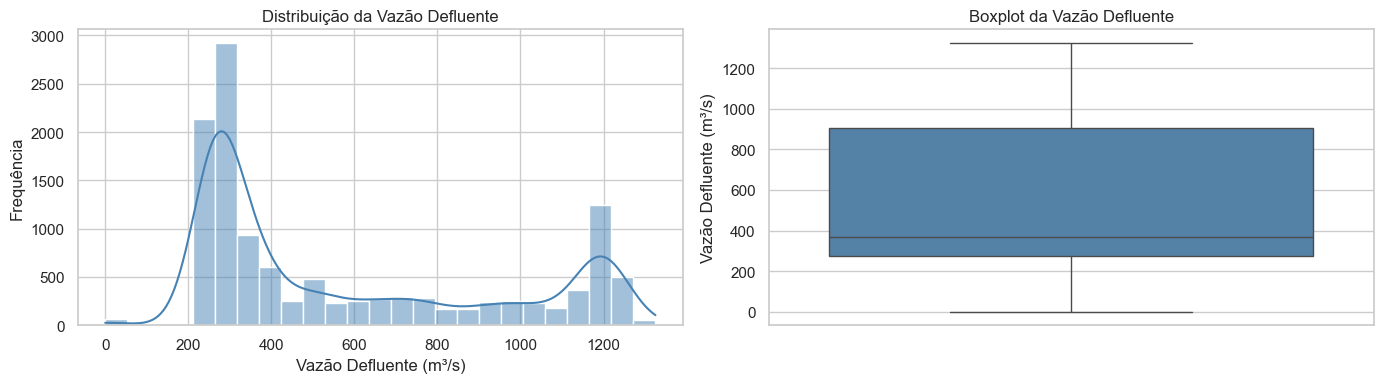


Estatísticas descritivas:
count    12102.000000
mean       572.230127
std        365.095975
min          0.000000
25%        277.000000
50%        370.000000
75%        905.000000
max       1325.000000
Name: val_vazaodefluente, dtype: float64

Assimetria (skewness): 0.7610
Curtose (kurtosis):    -1.0293


In [6]:
alvo = "val_vazaodefluente"

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histograma com KDE
sns.histplot(df[alvo], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribuição da Vazão Defluente")
axes[0].set_xlabel("Vazão Defluente (m³/s)")
axes[0].set_ylabel("Frequência")

# Boxplot
sns.boxplot(y=df[alvo], ax=axes[1], color="steelblue")
axes[1].set_title("Boxplot da Vazão Defluente")
axes[1].set_ylabel("Vazão Defluente (m³/s)")

plt.tight_layout()
plt.savefig("../notebooks/fig_distribuicao_alvo.png", dpi=150)
plt.show()

print("\nEstatísticas descritivas:")
print(df[alvo].describe())
print(f"\nAssimetria (skewness): {df[alvo].skew():.4f}")
print(f"Curtose (kurtosis):    {df[alvo].kurt():.4f}")

### Análise da Variável-Alvo:
- Distribuição **assimétrica positiva** (skewness = 0.76) com cauda longa à direita
- **Bimodalidade visível**: dois regimes operacionais distintos — período seco (~300 m³/s) e período chuvoso (~1200 m³/s), típico do ciclo hidrológico amazônico
- Média (572 m³/s) muito superior à mediana (370 m³/s), confirmando a assimetria
- Presença de valores mínimos zerados — momentos de operação reduzida ou parada
- Outliers visíveis no boxplot acima de ~1300 m³/s — serão investigados na seção de problemas
- **Decisão:** considerar aplicar transformação logarítmica (`log1p`) na modelagem para reduzir o efeito da assimetria

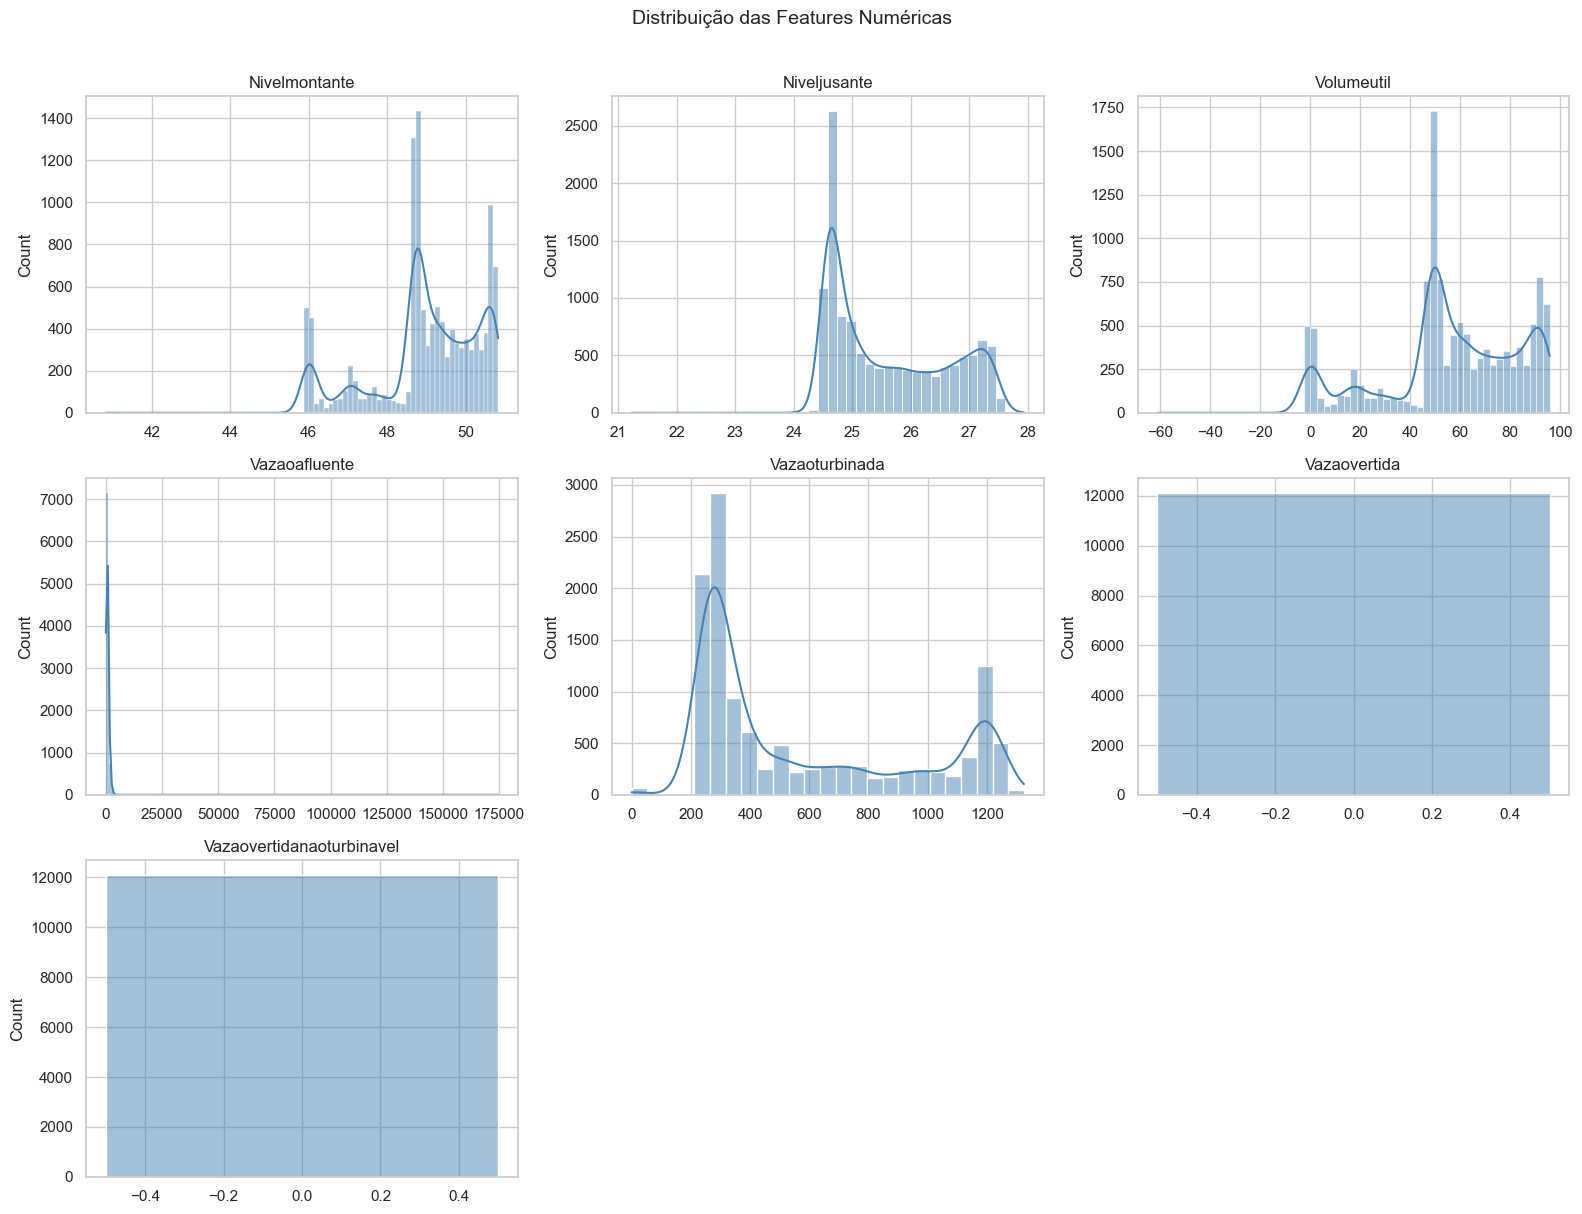

In [7]:
# Item 3 - Distribuições das features numéricas
features_numericas = [
    "val_nivelmontante", "val_niveljusante", "val_volumeutil",
    "val_vazaoafluente", "val_vazaoturbinada", "val_vazaovertida",
    "val_vazaovertidanaoturbinavel"
]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(features_numericas):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(col.replace("val_", "").replace("_", " ").title())
    axes[i].set_xlabel("")

# Desliga eixos extras
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Distribuição das Features Numéricas", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig("../notebooks/fig_distribuicao_features.png", dpi=150)
plt.show()

## 3. Distribuição das Features Numéricas

Análise dos histogramas com KDE para cada feature numérica:

- `val_nivelmontante`: distribuição bimodal (~46m e ~50m), refletindo dois regimes do reservatório (seco e cheio)
- `val_niveljusante`: concentração em torno de 24-25m com cauda à direita
- `val_volumeutil`: distribuição multimodal, indicando diferentes estados operacionais do reservatório ao longo do ano
- `val_vazaoafluente`: cauda extremamente longa à direita com valores até ~175.000 m³/s — requer investigação de outliers
- `val_vazaoturbinada`: distribuição similar à variável-alvo, indicando forte correlação esperada
- `val_vazaovertida` e `val_vazaovertidanaoturbinavel`: quase todos os valores são zero, com escala distorcida por poucos registros não-nulos — baixa variância, candidatas à remoção

In [8]:
# Investigar val_vazaoafluente e val_vazaovertida
print("val_vazaoafluente:")
print(df["val_vazaoafluente"].describe())
print(f"\nValores acima de 10.000: {(df['val_vazaoafluente'] > 10000).sum()}")

print("\nval_vazaovertida:")
print(df["val_vazaovertida"].describe())
print(f"\nValores diferentes de zero: {(df['val_vazaovertida'] != 0).sum()}")

print("\nval_vazaovertidanaoturbinavel:")
print(df["val_vazaovertidanaoturbinavel"].describe())
print(f"\nValores diferentes de zero: {(df['val_vazaovertidanaoturbinavel'] != 0).sum()}")

val_vazaoafluente:
count     12102.000000
mean        769.424227
std        1976.799197
min           0.000000
25%         289.000000
50%         652.000000
75%        1073.000000
max      174513.000000
Name: val_vazaoafluente, dtype: float64

Valores acima de 10.000: 3

val_vazaovertida:
count    12102.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: val_vazaovertida, dtype: float64

Valores diferentes de zero: 1

val_vazaovertidanaoturbinavel:
count    12079.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: val_vazaovertidanaoturbinavel, dtype: float64

Valores diferentes de zero: 24


### Investigação das features com comportamento anômalo:

- `val_vazaoafluente`: apenas 3 valores acima de 10.000 m³/s chegando ao máximo de 174.513 m³/s,
enquanto a mediana é 652 m³/s. Esses 3 registros são outliers extremos, provavelmente erros de medição
ou picos de cheia excepcionais. Serão removidos no pré-processamento.
- `val_vazaovertida`: coluna praticamente constante em zero (apenas 1 valor diferente de zero).
Coluna constante, sem variância útil para o modelo. Será removida.
- `val_vazaovertidanaoturbinavel`: apenas 24 valores diferentes de zero de 12.079 registros (~0.2%).
Coluna quase constante, sem informação relevante para o modelo. Será removida.

In [9]:
# Visualizar os 3 outliers extremos de val_vazaoafluente
print("Registros com val_vazaoafluente > 10.000:")
print(df[df["val_vazaoafluente"] > 10000][["din_instante", "val_vazaoafluente", "val_vazaodefluente"]])

Registros com val_vazaoafluente > 10.000:
             din_instante  val_vazaoafluente  val_vazaodefluente
476   2025-01-20 21:00:00           112415.0               279.0
8521  2025-12-24 17:00:00           174513.0              1176.0
10529 2026-03-18 09:00:00            25306.0                 0.0


### Outliers extremos confirmados em val_vazaoafluente:

- Registro 476 (20/01/2025 21h): afluência de 112.415 m³/s com defluente de apenas 279 m³/s - fisicamente impossível
- Registro 8521 (24/12/2025 17h): afluência de 174.513 m³/s com defluente de 1.176 m³/s - fisicamente impossível
- Registro 10529 (18/03/2026 09h): afluência de 25.306 m³/s com defluente zero - fisicamente impossível

Decisão: esses 3 registros são erros de medição/transmissão e serão removidos no pré-processamento.

In [10]:
# Item 4 - Features categóricas
print("Cardinalidade das features categóricas:")
cat_cols = ["id_subsistema", "nom_subsistema", "tip_reservatorio", 
            "nom_bacia", "id_reservatorio", "nom_reservatorio"]

for col in cat_cols:
    n = df[col].nunique()
    vals = df[col].unique()
    print(f"  {col}: {n} valor(es) único(s) -> {vals}")

Cardinalidade das features categóricas:
  id_subsistema: 1 valor(es) único(s) -> ['N']
  nom_subsistema: 1 valor(es) único(s) -> ['Norte']
  tip_reservatorio: 1 valor(es) único(s) -> ['Reservatório com Usina']
  nom_bacia: 1 valor(es) único(s) -> ['AMAZONAS']
  id_reservatorio: 1 valor(es) único(s) -> ['AMUHBB']
  nom_reservatorio: 1 valor(es) único(s) -> ['BALBINA']


## 4. Distribuição das Features Categóricas

Todas as features categóricas possuem apenas 1 valor único em todo o dataset:

- `id_subsistema`: "N"
- `nom_subsistema`: "Norte"
- `tip_reservatorio`: "Reservatório com Usina"
- `nom_bacia`: "AMAZONAS"
- `id_reservatorio`: "AMUHBB"
- `nom_reservatorio`: "BALBINA"

Isso é esperado, pois o dataset foi filtrado exclusivamente para a Usina de Balbina.
Colunas constantes não agregam nenhuma informação ao modelo e serão removidas
integralmente no pré-processamento. O mesmo vale para `cod_usina` (sempre 277.0).

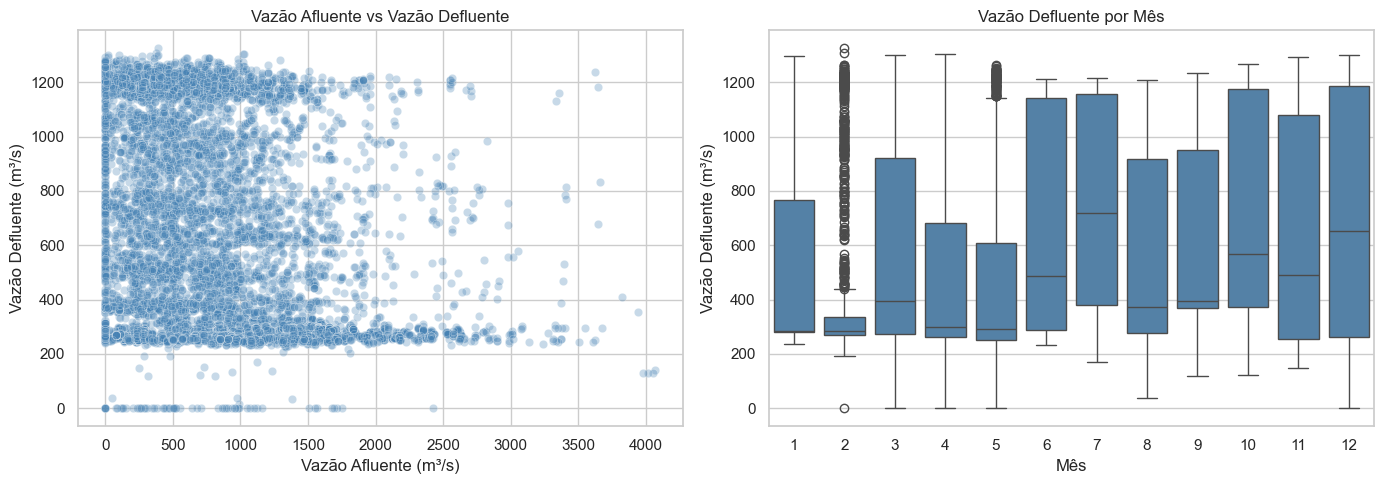

In [11]:
# Item 5 - Relação entre features e alvo
# Visualização 1: Vazão afluente vs defluente (scatterplot)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatterplot: afluente vs defluente
df_sem_outliers = df[df["val_vazaoafluente"] <= 10000]
sns.scatterplot(
    data=df_sem_outliers,
    x="val_vazaoafluente",
    y="val_vazaodefluente",
    alpha=0.3,
    ax=axes[0],
    color="steelblue"
)
axes[0].set_title("Vazão Afluente vs Vazão Defluente")
axes[0].set_xlabel("Vazão Afluente (m³/s)")
axes[0].set_ylabel("Vazão Defluente (m³/s)")

# Boxplot: vazão defluente por mês
sns.boxplot(
    data=df,
    x="mes",
    y="val_vazaodefluente",
    ax=axes[1],
    color="steelblue"
)
axes[1].set_title("Vazão Defluente por Mês")
axes[1].set_xlabel("Mês")
axes[1].set_ylabel("Vazão Defluente (m³/s)")

plt.tight_layout()
plt.savefig("../notebooks/fig_relacao_features_alvo.png", dpi=150)
plt.show()

## 5. Relações entre Features e Variável-Alvo

Duas visualizações foram escolhidas para explorar a relação das features com a variável-alvo:

**Scatterplot: Vazão Afluente vs Vazão Defluente**
- A relação nao é linear simples. Com afluências baixas (abaixo de 500 m³/s) a defluente
varia amplamente, indicando que a operação da usina depende de multiplas variáveis simultaneamente.
- Confirma que modelos lineares simples terao dificuldade e modelos baseados em árvore
(RandomForest, GradientBoosting) serao mais adequados.

**Boxplot: Vazão Defluente por Mês**
- Sazonalidade clara no ciclo hidrológico amazônico: fevereiro apresenta medianas baixas
(~300 m³/s) e junho-julho apresentam os maiores valores, refletindo o regime de chuvas da regiao.
- A feature `mes` sera importante para o modelo capturar esse comportamento sazonal.

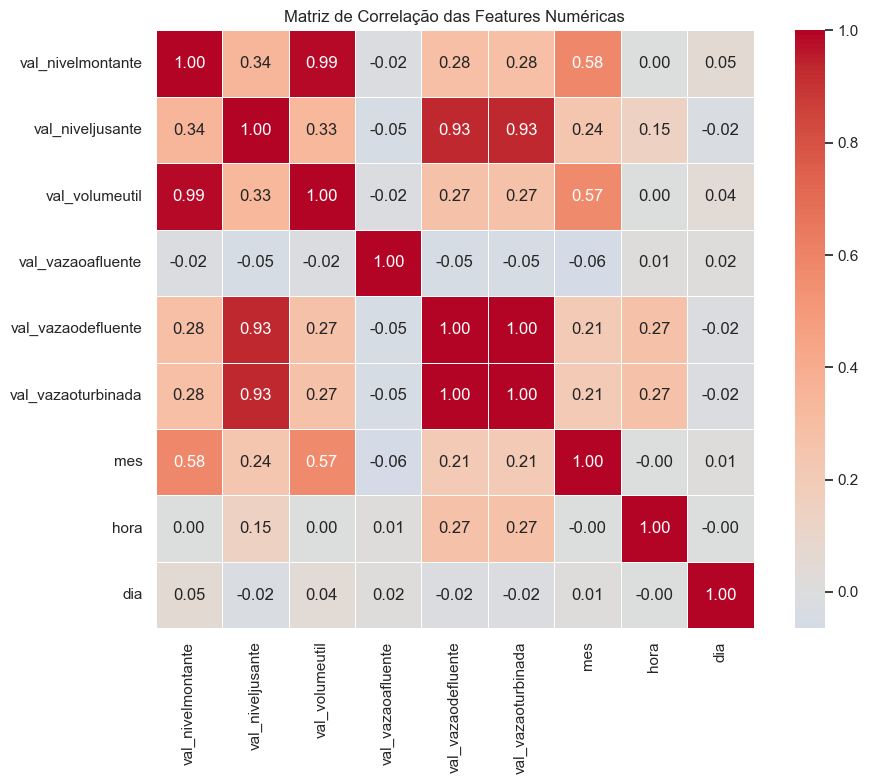

In [12]:
# Item 6 - Matriz de correlação
features_corr = [
    "val_nivelmontante", "val_niveljusante", "val_volumeutil",
    "val_vazaoafluente", "val_vazaodefluente", "val_vazaoturbinada",
    "mes", "hora", "dia"
]

corr = df[features_corr].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)
plt.title("Matriz de Correlação das Features Numéricas")
plt.tight_layout()
plt.savefig("../notebooks/fig_correlacao.png", dpi=150)
plt.show()

## 6. Matriz de Correlação

Correlações relevantes identificadas (|r| >= 0.7):

**Multicolinearidade alta:**
- `val_nivelmontante` e `val_volumeutil`: r = 0.99 - quase perfeita, representam a mesma informação
(nível do reservatório e volume armazenado). Manter apenas `val_nivelmontante` no modelo.
- `val_vazaodefluente` e `val_vazaoturbinada`: r = 1.00 - correlação perfeita. Isso indica que
`val_vazaoturbinada` é praticamente igual à variável-alvo, configurando **data leakage**.
Sera removida do modelo pois nao estaria disponível no momento da previsão.
- `val_niveljusante` e `val_vazaodefluente`: r = 0.93 - correlação muito alta. Investigar se
`val_niveljusante` tambem configura leakage (nivel a jusante é consequência da defluência).

**Correlações úteis com o alvo:**
- `val_niveljusante`: r = 0.93 - forte preditora
- `val_nivelmontante`: r = 0.28 - correlação moderada
- `mes`: r = 0.21 - captura sazonalidade

**Sem correlação relevante:**
- `hora`, `dia` e `val_vazaoafluente` apresentam correlação baixa com o alvo

In [13]:
# Item 7 - Identificação de problemas
print("=" * 50)
print("VALORES AUSENTES:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\n" + "=" * 50)
print("DUPLICATAS:")
print(f"Registros duplicados: {df.duplicated().sum()}")

print("\n" + "=" * 50)
print("OUTLIERS (IQR) nas features numericas:")
features_num = [
    "val_nivelmontante", "val_niveljusante", "val_volumeutil",
    "val_vazaoafluente", "val_vazaodefluente", "val_vazaoturbinada"
]
for col in features_num:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]
    print(f"  {col}: {len(outliers)} outliers ({len(outliers)/len(df)*100:.1f}%)")

VALORES AUSENTES:
val_nivelmontante                    1
val_niveljusante                     1
val_volumeutil                       1
val_vazaoafluente                    1
val_vazaodefluente                   1
val_vazaoturbinada                   1
val_vazaovertida                     1
val_vazaooutrasestruturas        11522
val_vazaotransferida             11519
val_vazaovertidanaoturbinavel       24
dtype: int64

DUPLICATAS:
Registros duplicados: 0

OUTLIERS (IQR) nas features numericas:
  val_nivelmontante: 1082 outliers (8.9%)
  val_niveljusante: 2 outliers (0.0%)
  val_volumeutil: 971 outliers (8.0%)
  val_vazaoafluente: 280 outliers (2.3%)
  val_vazaodefluente: 0 outliers (0.0%)
  val_vazaoturbinada: 0 outliers (0.0%)


## 7. Identificação de Problemas

**Valores Ausentes:**
- `val_nivelmontante`, `val_niveljusante`, `val_volumeutil`, `val_vazaoafluente`,
`val_vazaodefluente`, `val_vazaoturbinada`, `val_vazaovertida`: 1 nulo cada - insignificante,
corresponde ao mesmo registro com falha de transmissão
- `val_vazaooutrasestruturas`: 11.522 nulos (~95%) - coluna sera removida
- `val_vazaotransferida`: 11.519 nulos (~95%) - coluna sera removida
- `val_vazaovertidanaoturbinavel`: 24 nulos (~0.2%) - sera removida pois coluna quase constante (zero)

**Duplicatas:**
- Nenhum registro duplicado encontrado. Dataset integro nesse aspecto.

**Outliers (metodo IQR):**
- `val_nivelmontante`: 1.082 outliers (8.9%) - alta quantidade, reflete variacao natural
do nivel do reservatorio entre periodos seco e chuvoso, nao sao erros
- `val_volumeutil`: 971 outliers (8.0%) - mesma explicacao do nivel montante (r=0.99)
- `val_vazaoafluente`: 280 outliers (2.3%) - maioria sao variações naturais de cheia,
exceto os 3 registros extremos (>10.000 m³/s) que sao erros de medicao
- `val_niveljusante`: apenas 2 outliers - negligenciavel
- `val_vazaodefluente` e `val_vazaoturbinada`: sem outliers pelo metodo IQR

In [14]:
# Item 8 - Decisões de limpeza consolidadas
print("Resumo das decisoes de pre-processamento:")

colunas_remover = [
    "id_subsistema", "nom_subsistema", "tip_reservatorio",
    "nom_bacia", "id_reservatorio", "nom_reservatorio", "cod_usina",
    "val_vazaooutrasestruturas", "val_vazaotransferida",
    "val_vazaovertida", "val_vazaovertidanaoturbinavel",
    "val_volumeutil",       # multicolinear com val_nivelmontante (r=0.99)
    "val_vazaoturbinada",   # data leakage (r=1.00 com alvo)
]

print(f"\nColunas a remover ({len(colunas_remover)}):")
for c in colunas_remover: print(f"  - {c}")

print(f"\nOutliers extremos a remover:")
print(f"  - 3 registros com val_vazaoafluente > 10.000 m³/s")

print(f"\nNulos residuais (1 por coluna numerica):")
print(f"  - Imputacao pela mediana via SimpleImputer no Pipeline")

print(f"\nColunas finais para modelagem:")
features_finais = [
    "val_nivelmontante", "val_niveljusante",
    "val_vazaoafluente", "mes", "dia", "hora"
]
print(f"  {features_finais}")
print(f"\nVariavel-alvo: val_vazaodefluente")

Resumo das decisoes de pre-processamento:

Colunas a remover (13):
  - id_subsistema
  - nom_subsistema
  - tip_reservatorio
  - nom_bacia
  - id_reservatorio
  - nom_reservatorio
  - cod_usina
  - val_vazaooutrasestruturas
  - val_vazaotransferida
  - val_vazaovertida
  - val_vazaovertidanaoturbinavel
  - val_volumeutil
  - val_vazaoturbinada

Outliers extremos a remover:
  - 3 registros com val_vazaoafluente > 10.000 m³/s

Nulos residuais (1 por coluna numerica):
  - Imputacao pela mediana via SimpleImputer no Pipeline

Colunas finais para modelagem:
  ['val_nivelmontante', 'val_niveljusante', 'val_vazaoafluente', 'mes', 'dia', 'hora']

Variavel-alvo: val_vazaodefluente


## 8. Decisões de Limpeza

Para cada problema identificado, a decisão e justificativa:

**Colunas removidas por serem constantes (1 valor único):**
- `id_subsistema`, `nom_subsistema`, `tip_reservatorio`, `nom_bacia`,
`id_reservatorio`, `nom_reservatorio`, `cod_usina`: sem variância, nao agregam informacao ao modelo

**Colunas removidas por alta taxa de nulos (>95%):**
- `val_vazaooutrasestruturas` (95.2% nulos): inviavel para modelagem
- `val_vazaotransferida` (95.2% nulos): inviavel para modelagem

**Colunas removidas por serem quase constantes (zero):**
- `val_vazaovertida`: apenas 1 valor diferente de zero
- `val_vazaovertidanaoturbinavel`: apenas 24 valores diferentes de zero

**Colunas removidas por multicolinearidade:**
- `val_volumeutil`: r = 0.99 com `val_nivelmontante`, redundante

**Coluna removida por data leakage:**
- `val_vazaoturbinada`: r = 1.00 com a variavel-alvo, nao estaria disponivel no momento da previsao

**Outliers extremos:**
- 3 registros com `val_vazaoafluente` > 10.000 m³/s: erros de medicao confirmados,
serao removidos antes do split treino/teste

**Nulos residuais:**
- 1 nulo em cada coluna numerica principal: imputacao pela mediana via `SimpleImputer` dentro do Pipeline,
evitando data leakage

**Features finais para modelagem:**
`val_nivelmontante`, `val_niveljusante`, `val_vazaoafluente`, `mes`, `dia`, `hora`

**Variavel-alvo:** `val_vazaodefluente`

## 9. Insights da EDA

Lista dos principais achados que guiarao a modelagem:

1. **Bimodalidade da variavel-alvo**: dois regimes operacionais claros (seco ~300 m³/s e chuvoso
~1200 m³/s) sugerem que modelos baseados em arvore (RandomForest, GradientBoosting) capturarao
melhor esses padroes do que modelos lineares simples

2. **Data leakage identificado**: `val_vazaoturbinada` tem correlacao perfeita (r=1.00) com
`val_vazaodefluente` e foi removida. Manter essa feature geraria um modelo artificialmente perfeito
mas inutilizavel em producao

3. **Sazonalidade amazonica confirmada**: o boxplot por mes mostra variacao clara entre periodo
seco (fevereiro, medianas baixas) e chuvoso (junho-julho, medianas altas). A feature `mes` sera
importante para o modelo

4. **Multicolinearidade entre nivel e volume**: `val_nivelmontante` e `val_volumeutil` tem r=0.99,
mantendo apenas `val_nivelmontante` para evitar redundancia e instabilidade nos modelos lineares

5. **Outliers extremos em val_vazaoafluente**: 3 registros com valores acima de 10.000 m³/s sao
erros de medicao fisicamente impossiveis e serao removidos antes da modelagem

In [15]:
# Verificação final do dataset após decisões
df_clean = df.copy()

# Remove outliers extremos
df_clean = df_clean[df_clean["val_vazaoafluente"] <= 10000]

# Remove colunas desnecessárias
colunas_remover = [
    "id_subsistema", "nom_subsistema", "tip_reservatorio",
    "nom_bacia", "id_reservatorio", "nom_reservatorio", "cod_usina",
    "val_vazaooutrasestruturas", "val_vazaotransferida",
    "val_vazaovertida", "val_vazaovertidanaoturbinavel",
    "val_volumeutil", "val_vazaoturbinada", "din_instante", "ano"
]
df_clean = df_clean.drop(columns=colunas_remover)

print("Shape final:", df_clean.shape)
print("\nColunas finais:")
print(list(df_clean.columns))
print("\nNulos restantes:")
print(df_clean.isnull().sum())
print("\nPrimeiras linhas do dataset limpo:")
print(df_clean.head())

Shape final: (12099, 7)

Colunas finais:
['val_nivelmontante', 'val_niveljusante', 'val_vazaoafluente', 'val_vazaodefluente', 'mes', 'dia', 'hora']

Nulos restantes:
val_nivelmontante     0
val_niveljusante      0
val_vazaoafluente     0
val_vazaodefluente    0
mes                   0
dia                   0
hora                  0
dtype: int64

Primeiras linhas do dataset limpo:
   val_nivelmontante  val_niveljusante  val_vazaoafluente  val_vazaodefluente  \
0              46.04             24.60              287.0               284.0   
1              46.04             24.59              287.0               284.0   
2              46.04             24.59              287.0               284.0   
3              46.04             24.60              287.0               284.0   
4              46.04             24.59              287.0               284.0   

   mes  dia  hora  
0    1    1     1  
1    1    1     2  
2    1    1     3  
3    1    1     4  
4    1    1     5  


In [16]:
# Salvar dataset processado
import os
os.makedirs("../data/processed", exist_ok=True)
df_clean.to_csv("../data/processed/balbina_processado.csv", index=False, encoding="utf-8-sig", sep=";")
print("Dataset processado salvo em: data/processed/balbina_processado.csv")
print(f"\nResumo final:")
print(f"  Total de registros : {len(df_clean):,}")
print(f"  Features           : {list(df_clean.columns[:-1])}")  
print(f"  Variavel-alvo      : val_vazaodefluente")
print(f"  Nulos              : {df_clean.isnull().sum().sum()}")
print(f"  Duplicatas         : {df_clean.duplicated().sum()}")

Dataset processado salvo em: data/processed/balbina_processado.csv

Resumo final:
  Total de registros : 12,099
  Features           : ['val_nivelmontante', 'val_niveljusante', 'val_vazaoafluente', 'val_vazaodefluente', 'mes', 'dia']
  Variavel-alvo      : val_vazaodefluente
  Nulos              : 0
  Duplicatas         : 22


In [17]:
# Investigar duplicatas
duplicatas = df_clean[df_clean.duplicated(keep=False)]
print(f"Registros duplicados: {len(duplicatas)}")
print("\nExemplo de duplicatas:")
print(duplicatas.head(10))

Registros duplicados: 44

Exemplo de duplicatas:
     val_nivelmontante  val_niveljusante  val_vazaoafluente  \
142              46.08             24.60              280.0   
143              46.08             24.60              280.0   
238              46.09             24.59               93.0   
239              46.09             24.59               93.0   
262              46.08             24.59               96.0   
263              46.08             24.59               96.0   
502              45.95             24.56               95.0   
503              45.95             24.56               95.0   
550              45.94             24.57               96.0   
551              45.94             24.57               96.0   

     val_vazaodefluente  mes  dia  hora  
142               278.0    1    6    23  
143               278.0    1    6    23  
238               283.0    1   10    23  
239               283.0    1   10    23  
262               283.0    1   11    23  
263  

In [18]:
# Verificar se todas as duplicatas são na hora 23
print(f"Duplicatas por hora:")
print(duplicatas["hora"].value_counts())

Duplicatas por hora:
hora
23    44
Name: count, dtype: int64


### Duplicatas identificadas:
- 22 registros duplicados (44 linhas), todos na hora 23:00
- Causa: sobreposição entre o ultimo registro de um mes e o primeiro do mes seguinte
nos arquivos mensais originais da ANEEL
- Decisao: remover duplicatas mantendo o primeiro registro (`keep="first"`)

In [19]:
# Remover duplicatas
df_clean = df_clean.drop_duplicates(keep="first").reset_index(drop=True)

print(f"Shape apos remocao de duplicatas: {df_clean.shape}")
print(f"Duplicatas restantes: {df_clean.duplicated().sum()}")

# Salvar dataset processado final
df_clean.to_csv("../data/processed/balbina_processado.csv", index=False, encoding="utf-8-sig", sep=";")

print("\nDataset processado salvo em: data/processed/balbina_processado.csv")
print(f"\nResumo final:")
print(f"  Total de registros : {len(df_clean):,}")
print(f"  Features           : {list(df_clean.columns.drop('val_vazaodefluente'))}")
print(f"  Variavel-alvo      : val_vazaodefluente")
print(f"  Nulos              : {df_clean.isnull().sum().sum()}")
print(f"  Duplicatas         : {df_clean.duplicated().sum()}")

Shape apos remocao de duplicatas: (12077, 7)
Duplicatas restantes: 0

Dataset processado salvo em: data/processed/balbina_processado.csv

Resumo final:
  Total de registros : 12,077
  Features           : ['val_nivelmontante', 'val_niveljusante', 'val_vazaoafluente', 'mes', 'dia', 'hora']
  Variavel-alvo      : val_vazaodefluente
  Nulos              : 0
  Duplicatas         : 0
